# Simulator parameters — Phase 4

## Objective

The simulator adds up lap times and pit stops for one driver in one race, and ranks the strategies by the total. Phases 2 and 3
built the lap-time models. This notebook measures **everything else the simulator needs**, one table per circuit:

1. the **pit-stop loss** under green flag, as a distribution (this notebook, sections 2-4);
2. safety cars and virtual safety cars: how often, and when;
3. the pit-stop loss **under** a neutralisation;
4. the stint lengths observed on each circuit, which bound what the simulator may propose.

Items 2-4 are added in later sections, one decision at a time.

## The window

The simulated season is **2025** (decided 2026-11-12). The lap-time models are fitted on 2023-2024, so every parameter here is
measured on **2023-2024** (`simparams.PARAM_YEARS`), and the real 2025 races stay untouched for step 6, where the recommendations are
checked. 2026 is not used. This differs from phase 1, whose exported table is fitted on 2023-2025 (pit loss on 2023-2026): that
table is not the simulator's input.

## Code

The stops come from `f1data.pit_entries()`, the losses from `simparams.stop_losses()`. Nothing is rebuilt in the notebook.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import f1data
import simparams

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

raw = f1data.load_raw(verbose=False)
window = raw.races[raw.races["date_start"].dt.year.isin(simparams.PARAM_YEARS)]
dry = f1data.dry_keys(raw.weather, raw.races)
print(f"{len(window)} races held in {simparams.PARAM_YEARS[0]}-{simparams.PARAM_YEARS[-1]}, "
      f"{window['session_key'].isin(dry).sum()} of them dry")

47 races held in 2023-2024, 42 of them dry


## 2. The pit-stop loss, and the check against phase 1

**Definition** (phase 1, `data-viz.ipynb` section 7, unchanged): the loss of a stop is

    loss = in-lap time + out-lap time - 2 x reference

where the reference is the median of the same driver's clean laps within 3 laps of the stop (at least 2 of them). A stop is kept when
the race is dry, neither the in-lap nor the out-lap is under safety car, VSC or red flag, and the loss is between 10 and 45 s (outside
that it is a penalty served, a repair or a botched stop).

**What changes**: the stops. Seven races of 2023 carry no row in the `pit` endpoint, so phase 1 measured no stop there. Their stops
are now read off `stints`: the last lap of a stint that another stint follows is the in-lap (`f1data.pit_entries()`, source
`stints`).

**The check**: measured on the `pit` rows only, over every dry race of 2023-2026, the function must give back phase 1's figure,
1 819 stops at a mean of 23.0 s. The cell fails otherwise.

In [2]:
phase1 = simparams.stop_losses(raw, entries=f1data.pit_entries(raw.pit))
k = phase1[phase1["kept"]]
print(f"pit rows only, dry races 2023-2026: {len(k):,} stops kept over {k['session_key'].nunique()} races, "
      f"mean loss {k['loss'].mean():.2f} s")
assert len(k) == 1819 and round(k["loss"].mean(), 1) == 23.0, "does not reproduce phase 1"
print("reproduces phase 1 (data-viz.ipynb section 7: 1819 stops, 23.0 s).")

stops = simparams.stop_losses(raw)                         # pit rows + stops read off stints
w = stops[stops["year"].isin(simparams.PARAM_YEARS)]
print(f"\n{simparams.PARAM_YEARS[0]}-{simparams.PARAM_YEARS[-1]}, dry races: {len(w):,} stops entered")
print(w.groupby("source").agg(entered=("kept", "size"), neutralised=("neutral", "sum"),
                              kept=("kept", "sum")).to_string())
lost = w[~w["kept"] & ~w["neutral"]]
few = lost["ref_laps"] < simparams.REF_MIN_LAPS
missing = ~few & lost["loss"].isna()
outside = ~few & ~missing
print(f"\nnot neutralised but not kept: {len(lost)} = {int(few.sum())} with too few reference laps "
      f"+ {int(missing.sum())} with a missing in-lap or out-lap time "
      f"+ {int(outside.sum())} outside {simparams.LOSS_MIN:.0f}-{simparams.LOSS_MAX:.0f} s")

pit rows only, dry races 2023-2026: 1,819 stops kept over 75 races, mean loss 22.99 s
reproduces phase 1 (data-viz.ipynb section 7: 1819 stops, 23.0 s).



2023-2024, dry races: 1,476 stops entered
        entered  neutralised  kept
source                            
pit        1295          310   964
stints      181           90    90

not neutralised but not kept: 22 = 2 with too few reference laps + 0 with a missing in-lap or out-lap time + 20 outside 10-45 s


## 3. Are the stops read off `stints` the same stops?

The rule "last lap of a stint followed by another" was checked once on lap counts. It is checked here on the quantity that matters,
the loss: on the 2023-2024 races that **do** have `pit` rows, the stops are measured a second time from `stints` alone, and the two
sets are matched stop by stop.

In [3]:
races = set(raw.races["session_key"])
from_stints = f1data.pit_entries(raw.pit.iloc[0:0], raw.stints[raw.stints["session_key"].isin(races)])
alt = simparams.stop_losses(raw, entries=from_stints)
alt = alt[alt["session_key"].isin(set(raw.pit["session_key"])) & alt["year"].isin(simparams.PARAM_YEARS)]
ref = w[w["source"] == "pit"]

m = ref.merge(alt[simparams.KEY + ["loss", "kept"]], on=simparams.KEY, how="outer",
              suffixes=("_pit", "_stints"), indicator=True)
print("stops matched between the two sources:", m["_merge"].value_counts().to_dict())
both = m[m["kept_pit"].eq(True) & m["kept_stints"].eq(True)]
print(f"kept by both: {len(both)}, identical loss on all of them: "
      f"{bool(np.allclose(both['loss_pit'], both['loss_stints']))}")
for name, x in [("from pit rows", ref[ref["kept"]]["loss"]), ("from stints", alt[alt["kept"]]["loss"])]:
    print(f"  {name:14s} {len(x):4d} kept, median {x.median():.2f} s, mean {x.mean():.2f} s")

print("\nthe races without pit rows, what stints adds:")
rec = w[w["source"] == "stints"]
print(rec.groupby(["circuit", "year"]).agg(entered=("kept", "size"), neutralised=("neutral", "sum"),
                                           kept=("kept", "sum"))
      .join(rec[rec["kept"]].groupby(["circuit", "year"])["loss"].median().rename("median kept (s)"))
      .round(2).to_string())

stops matched between the two sources: {'both': 1294, 'right_only': 7, 'left_only': 1}
kept by both: 963, identical loss on all of them: True
  from pit rows   964 kept, median 21.66 s, mean 22.63 s
  from stints     963 kept, median 21.66 s, mean 22.63 s

the races without pit rows, what stints adds:
                entered  neutralised  kept  median kept (s)
circuit   year                                             
Baku      2023       23           10    13            21.33
Jeddah    2023       24           12    12            20.68
Melbourne 2023       64           62     2            20.01
Miami     2023       20            0    19            19.71
Sakhir    2023       50            6    44            23.05


## 4. The green-flag loss per circuit, 2023-2024

One row per circuit over the kept stops, and an `ALL` row for the calendar. The simulator needs a **distribution**, not a mean
(`docs/02-decisions-log.md`): the mean is pulled up by a tail of slow stops, so the table gives the median, the spread (sd and
quartiles), the 90th percentile and the share of stops above 30 s.

                    races  stops  median   mean    sd    q25    q75    q90  share > 30 s
circuit                                                                                 
Austin                  2     58   20.49  21.03  2.31  19.74  21.75  23.44          0.02
Baku                    2     31   21.33  22.73  4.30  20.48  22.81  28.82          0.10
Catalunya               2     84   22.35  22.45  1.78  21.39  23.34  24.55          0.00
Hungaroring             2     76   19.94  20.24  1.92  18.89  21.17  22.86          0.00
Imola                   1     25   27.32  27.79  2.22  26.64  27.83  29.32          0.08
Interlagos              1     33   21.40  21.41  1.38  20.53  22.08  22.88          0.00
Jeddah                  2     16   20.60  23.62  6.49  19.85  23.70  32.71          0.19
Las Vegas               2     55   21.97  22.91  3.82  20.84  23.48  26.57          0.05
Lusail                  2     56   27.30  28.25  3.11  26.69  28.94  31.58          0.16
Melbourne            


circuits: 24; with one race only: ['Imola', 'Interlagos', 'Monte Carlo', 'Montreal', 'Shanghai', 'Silverstone', 'Zandvoort']
stops per circuit: min 7 (Monte Carlo), median 36, max 84 (Catalunya)
median per circuit from 17.6 s (Spa-Francorchamps) to 28.9 s (Singapore); mean minus median, calendar: +0.98 s


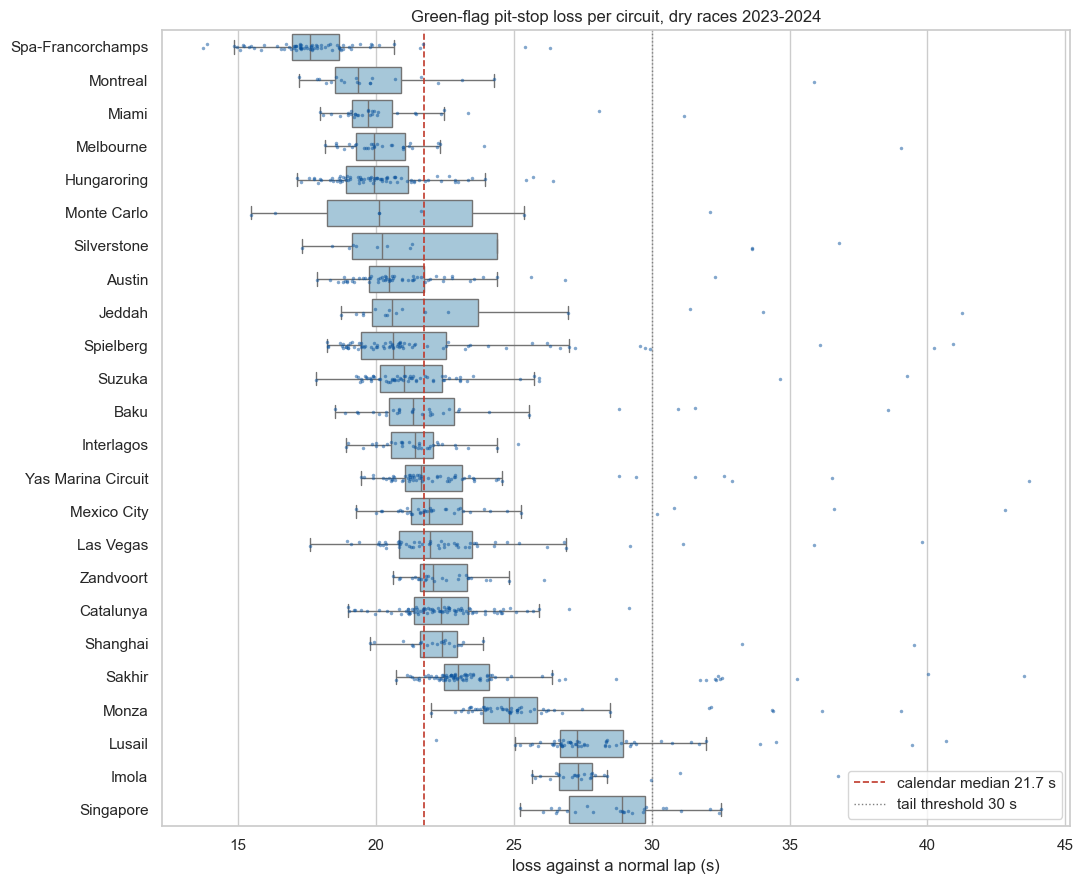

In [4]:
kept = w[w["kept"]]
table = simparams.loss_table(w)
print(table.round(2).to_string())

order = table.drop(index="ALL").sort_values("median").index
fig, ax = plt.subplots(figsize=(11, 9))
sns.boxplot(data=kept, y="circuit", x="loss", order=order, showfliers=False, color="#9ecae1", ax=ax)
sns.stripplot(data=kept, y="circuit", x="loss", order=order, size=2.5, color="#08519c", alpha=0.5, ax=ax)
ax.axvline(table.loc["ALL", "median"], color="#c0392b", ls="--", lw=1.2,
           label=f"calendar median {table.loc['ALL', 'median']:.1f} s")
ax.axvline(simparams.TAIL, color="#7f7f7f", ls=":", lw=1, label=f"tail threshold {simparams.TAIL:.0f} s")
ax.set(title="Green-flag pit-stop loss per circuit, dry races 2023-2024",
       xlabel="loss against a normal lap (s)", ylabel="")
ax.legend(loc="lower right")
fig.tight_layout()

thin = table.drop(index="ALL")
print(f"\ncircuits: {len(thin)}; with one race only: {sorted(thin.index[thin['races'] == 1])}")
print(f"stops per circuit: min {thin['stops'].min()} ({thin['stops'].idxmin()}), median {thin['stops'].median():.0f}, "
      f"max {thin['stops'].max()} ({thin['stops'].idxmax()})")
print(f"median per circuit from {thin['median'].min():.1f} s ({thin['median'].idxmin()}) to "
      f"{thin['median'].max():.1f} s ({thin['median'].idxmax()}); mean minus median, calendar: "
      f"{table.loc['ALL', 'mean'] - table.loc['ALL', 'median']:+.2f} s")

### What the table says

**The measurement holds.** On the `pit` rows the function gives back phase 1 exactly (1 819 stops, 23.0 s). On the 2023-2024
races that carry both sources, the stops read off `stints` are the `pit` stops: 1 294 of the 1 295 are found (plus 7 stint
boundaries with no `pit` row, and 1 `pit` row missed), and the 963 stops kept by both have identical losses. Reading the races
with no `pit` row from `stints` is therefore the same measurement on those races, not an approximation of it.

**What `stints` adds: 90 kept stops from five races of 2023** (Sakhir 44, Miami 19, Baku 13, Jeddah 12, Melbourne 2). Melbourne
adds almost nothing: 62 of its 64 stops sit on neutralised laps. The medians of the recovered stops (19.7 to 23.1 s) are inside the
range of the other races. Imola 2023 counts as dry because it has no weather row, but it has no lap either (the race was not held),
so it contributes nothing: that is why the `ALL` row reads 41 races out of the 42 called dry.

**A quarter of the stops are not in this table**: 400 of the 1 476 (27 %) have their in-lap or out-lap under a safety car, a VSC or a
red flag. Their loss is a different quantity and is the subject of a later section.

**The calendar, 1 054 stops**: median 21.75 s, mean 22.72 s. The mean sits 0.98 s above the median because of a tail of slow stops:
the middle half lies between 20.05 and 24.03 s, the 90th percentile is at 27.8 s, and 6 % of stops exceed 30 s.

**Per circuit, the median runs from 17.6 s (Spa-Francorchamps) to 28.9 s (Singapore)**, 11.3 s apart. Phase 1 quoted 20.0 to 28.1 s,
but on means and over 2023-2026: the two windows differ, so the two ranges do not compare one to one.

**The spread differs as much as the level.** The middle half of the stops spans under 2 s at Interlagos (1.55 s) and Zandvoort
(1.72 s) and over 5 s at Silverstone (5.24 s). A fixed threshold reads the tail badly across circuits: 30 s is barely above
Singapore's median (28.9 s, half a standard deviation) and 12 s above Spa's (17.6 s). Read against each circuit's own median, the 90th
percentile sits 1.5 s above it at Interlagos and 13.4 s above it at Silverstone.

**Seven circuits rest on a single race** (Imola, Interlagos, Monte Carlo, Montreal, Shanghai, Silverstone, Zandvoort), and the
widest rows are thin ones: Silverstone (12 stops, sd 6.97 s), Jeddah (16 stops, sd 6.49 s), Monte Carlo (7 stops, sd 5.68 s). How
much a circuit with few stops should keep its own value, rather than borrow from the calendar, is the next decision.

**What this table assumes**: that the pit lane of a circuit in 2025 costs what it cost in 2023-2024. That is not checked here (2025 is
not read in this notebook); step 6 will show it if it fails.